# Random Forest Multi Classifiers

Andrew E. Davidson   
aedavids@ucsc.edu  
Date: 2025-10-14.  
Copyright (c) 2020-2023, Regents of the University of California All rights reserved.  
https://polyformproject.org/licenses/noncommercial/1.0.0  

Trains 4 and 5 cancer random forest models. See cell [7] to select which model to run

creates.     
- Extended Data Figure 4: Confusion matrices comparing synthetic training, validation, and real holdout performance
- Extended Data Figure 11: Random Forest Multi-Classifier Feature Selection
- saves trained models

In [1]:
defaultNotebookName="multiClassifiers"

from cliUtilities import configLogging
import logging

# rootLogger = configLogging(logLevel="INFO")
rootLogger = configLogging(logLevel="WARN")
logger = logging.getLogger(__name__)

2026-11-20 13:09:30,543 WARNING cliUtilities.py configLogging() line:61] [BEGIN]
2026-11-20 13:09:30,544 WARNING cliUtilities.py configLogging() line:67] [PYTHONPATH : /private/home/aedavids/graceM/src/python:/private/home/aedavids/graceM/src/jupyterNotebooks]
2026-11-20 13:09:30,545 WARNING cliUtilities.py configLogging() line:68] [FILE: /private/home/aedavids/graceM/src/python/cliUtilities.py]
2026-11-20 13:09:30,545 WARNING cliUtilities.py configLogging() line:69] [PWD: /private/home/aedavids/graceM/src/jupyterNotebooks]


In [2]:
from copy import deepcopy
import glob
from IPython.display import display
# from IPython.display import HTML
from IPython.display import Image

import matplotlib.pyplot as plt
from matplotlib import figure

import os
import pandas as pd
from pathlib import Path
import pprint as pp
import time
# local imports
from notebookUtils import appendToPYTHONPATH, getNotebookName

ORIG_PYTHONPATH = os.environ['PYTHONPATH']

extraRNA_PythonPath1 = '/private/home/aedavids/extraCellularRNA' 
extraRNA_PythonPath2 = '/private/home/aedavids/extraCellularRNA/src'
appendToPYTHONPATH([extraRNA_PythonPath1, extraRNA_PythonPath2]) 

from archive.dataTypes import  DiagnosticBundle, ModelConfig
from archive.saveDataTypes import archive 
from archive.archiveUtilities import  saveFigure

from models.configMLWorkflow import  configConfusionPanel, configMultiCalculateSensitivityAtSpecificity ,configEvaluate
from models.configMLWorkflow import configMultiLoad, configROCPanel, configVolcanoPanel
from models.mlWorkflow import loadAndSplit, trainRandomForest
from plots.plotPanel import combineFigures, displayPDFInNotebook
from plots.plotPanel import make_panel
from plots.plotUtilities import saveDataFrameImage
from plots.volcanoPlotWithBaseMean import volcanoPlotWithBaseMean

theMeaningOfLife = 42

notebook_start_time = time.time()
print("⏱️ Notebook started.")

2026-11-20 13:09:31,458 WARNING notebookUtils.py appendToPYTHONPATH() line:40] [Updated PYTHONPATH: /private/home/aedavids/graceM/src/python:/private/home/aedavids/graceM/src/jupyterNotebooks:/private/home/aedavids/extraCellularRNA:/private/home/aedavids/extraCellularRNA/src]


⏱️ Notebook started.


/private/home/aedavids/miniconda3/envs/graceM/lib/python3.13/site-packages/fitz/__init__.py:17: FutureWarning: The `fitz` API is deprecated and will be removed in future. Use `import pymupdf` instead.
  warnings.warn(


In [3]:
notebookName, notebookDir = getNotebookName(defaultNotebookName)
print(f'notebookName: {notebookName}')
print(f'notebookDir: {notebookDir}')
notebookOutDir = f'{notebookDir}/{notebookName}.out'

notebookName: multiClassifier
notebookDir: /private/home/aedavids/graceM/src/jupyterNotebooks


In [4]:
# _G : global use to insure we do not pick up globals in function by accident 
# durring refactoring

simulatedDataRootDir_G = "/private/groups/kimlab/aedavids/fagazi/simulatedData"
scratchDataRootDir_G = "/scratch/aedavids/fagazi/simulatedData"

realDataRoot_G = "/private/groups/kimlab/data/elife"
realDataPath_G = f'{realDataRoot_G}/elife_all_norm_counts_2023-05-18.csv'
realMetaDataPath_G = f'{realDataRoot_G}/elife_scaled_metaData_2023-05-18.csv'

In [5]:
elifeMultiClassifierFrom400BinaryDropHealthy_Lung_G = ModelConfig(
                        dataSetName = "elifeMultiClassifierFrom400BinaryDropHealthy+Lung",
                        rootOutDir = notebookOutDir,
                        simulatedDataPath = f"{scratchDataRootDir_G}/elifeMultiClassifierFrom400Binary.sh.out_best400_results",
                        realDataPath = realDataPath_G,
                        realMetaDataPath = realMetaDataPath_G,
                        deseqResultsType = 'results',
                        
                        # ROC, sensitivity, specificity, confusion plots expect
                        # the positive condition to be labeled 1, and the negative
                        # test results labeled 0.
                        # make sure categories[0] is the negative diagnostic test class
                        # "Healthy_donor", "Lung_Cancer",
                        categories = [ "Colorectal_Cancer", "Esophagus_Cancer",  
                                        "Liver_Cancer",  "Stomach_Cancer" ],
                    )


In [6]:
elifeMultiClassifierFrom300_1vsAllRelaxedDropHealthy_G = ModelConfig(
                        dataSetName = "elifeMultiClassifierFrom300_1vsAllRelaxedDropHealthy",
                        rootOutDir = notebookOutDir,
                        simulatedDataPath = f"{scratchDataRootDir_G}/elifeMultiClassifierFrom300_1vsAllRelaxed.sh.out_best300_results",
                        realDataPath = realDataPath_G,
                        realMetaDataPath = realMetaDataPath_G,
                        deseqResultsType = 'results',
                        
                        # ROC, sensitivity, specificity, confusion plots expect
                        # the positive condition to be labeled 1, and the negative
                        # test results labeled 0.
                        # "Healthy_donor",
                        # make sure categories[0] is the negative diagnostic test class
                        categories = [  "Colorectal_Cancer", "Esophagus_Cancer",  
                                        "Liver_Cancer", "Lung_Cancer", "Stomach_Cancer" ],
                    )

In [7]:
# select either the 4 or 5 cancer model configuration
runConfig_G = elifeMultiClassifierFrom400BinaryDropHealthy_Lung_G # 4 cancer
# runConfig_G = elifeMultiClassifierFrom300_1vsAllRelaxedDropHealthy_G # 5 cancer

## Train Multi classifier 

In [8]:
# ROC, sensitivity, specificity, confusion plots expect
# the positive condition to be labeled 1, and the negative
# test results labeled 0.
# make sure categories[0] is the negative diagnostic test class

configMultiLoad(runConfig_G)

2026-11-20 13:09:33,105 WARNING loadCounts.py loadDataFrame() line:164] [loading : /scratch/aedavids/fagazi/simulatedData/elifeMultiClassifierFrom400Binary.sh.out_best400_results/formatSynthetics.py.out/X.pandas.h5]
2026-11-20 13:09:38,247 WARNING loadCounts.py loadDataFrame() line:164] [loading : /scratch/aedavids/fagazi/simulatedData/elifeMultiClassifierFrom400Binary.sh.out_best400_results/formatSynthetics.py.out/y.pandas.h5]
2026-11-20 13:09:41,631 WARNING loadCounts.py loadDataFrame() line:181] [loading : /private/groups/kimlab/data/elife/elife_all_norm_counts_2023-05-18.csv]
2026-11-20 13:09:42,930 WARNING loadCounts.py loadDataFrame() line:181] [loading : /private/groups/kimlab/data/elife/elife_scaled_metaData_2023-05-18.csv]


In [9]:
%%time
print(f'{runConfig_G.dataSetName}')
trainRandomForest( runConfig_G.dataDict )

2026-11-20 13:09:43,035 WARNING mlWorkflow.py trainRandomForest() line:430] [XDF.shape : (121999, 1525) y.shape : (121999,)]


elifeMultiClassifierFrom400BinaryDropHealthyLung
multi
CPU times: user 3min 22s, sys: 272 ms, total: 3min 22s
Wall time: 3min 22s


## Evaluate  classifiers

In [10]:
print(f'{runConfig_G.dataSetName}')
configEvaluate( runConfig_G)

elifeMultiClassifierFrom400BinaryDropHealthyLung
diganosis : multi dataSet : simTrain


2026-11-20 13:13:11,793 WARNING archiveUtilities.py saveFigure() line:200] [saved : /private/home/aedavids/graceM/src/jupyterNotebooks/multiClassifier.out/elifeMultiClassifierFrom400BinaryDropHealthyLung/img/confusionMatrix_multi-simTrain.png]
2026-11-20 13:13:12,757 WARNING archiveUtilities.py saveFigure() line:203] [saved : /private/home/aedavids/graceM/src/jupyterNotebooks/multiClassifier.out/elifeMultiClassifierFrom400BinaryDropHealthyLung/img/confusionMatrix_multi-simTrain.pdf]
2026-11-20 13:13:18,736 WARNING archiveUtilities.py saveFigure() line:200] [saved : /private/home/aedavids/graceM/src/jupyterNotebooks/multiClassifier.out/elifeMultiClassifierFrom400BinaryDropHealthyLung/img/roc_multi-simTrain.png]
2026-11-20 13:13:18,855 WARNING archiveUtilities.py saveFigure() line:203] [saved : /private/home/aedavids/graceM/src/jupyterNotebooks/multiClassifier.out/elifeMultiClassifierFrom400BinaryDropHealthyLung/img/roc_multi-simTrain.pdf]


diganosis : multi dataSet : simVal


2026-11-20 13:13:21,577 WARNING archiveUtilities.py saveFigure() line:200] [saved : /private/home/aedavids/graceM/src/jupyterNotebooks/multiClassifier.out/elifeMultiClassifierFrom400BinaryDropHealthyLung/img/confusionMatrix_multi-simVal.png]
2026-11-20 13:13:22,429 WARNING archiveUtilities.py saveFigure() line:203] [saved : /private/home/aedavids/graceM/src/jupyterNotebooks/multiClassifier.out/elifeMultiClassifierFrom400BinaryDropHealthyLung/img/confusionMatrix_multi-simVal.pdf]
2026-11-20 13:13:24,872 WARNING archiveUtilities.py saveFigure() line:200] [saved : /private/home/aedavids/graceM/src/jupyterNotebooks/multiClassifier.out/elifeMultiClassifierFrom400BinaryDropHealthyLung/img/roc_multi-simVal.png]
2026-11-20 13:13:24,992 WARNING archiveUtilities.py saveFigure() line:203] [saved : /private/home/aedavids/graceM/src/jupyterNotebooks/multiClassifier.out/elifeMultiClassifierFrom400BinaryDropHealthyLung/img/roc_multi-simVal.pdf]


diganosis : multi dataSet : simTest


2026-11-20 13:13:27,890 WARNING archiveUtilities.py saveFigure() line:200] [saved : /private/home/aedavids/graceM/src/jupyterNotebooks/multiClassifier.out/elifeMultiClassifierFrom400BinaryDropHealthyLung/img/confusionMatrix_multi-simTest.png]
2026-11-20 13:13:28,733 WARNING archiveUtilities.py saveFigure() line:203] [saved : /private/home/aedavids/graceM/src/jupyterNotebooks/multiClassifier.out/elifeMultiClassifierFrom400BinaryDropHealthyLung/img/confusionMatrix_multi-simTest.pdf]
2026-11-20 13:13:31,239 WARNING archiveUtilities.py saveFigure() line:200] [saved : /private/home/aedavids/graceM/src/jupyterNotebooks/multiClassifier.out/elifeMultiClassifierFrom400BinaryDropHealthyLung/img/roc_multi-simTest.png]
2026-11-20 13:13:31,353 WARNING archiveUtilities.py saveFigure() line:203] [saved : /private/home/aedavids/graceM/src/jupyterNotebooks/multiClassifier.out/elifeMultiClassifierFrom400BinaryDropHealthyLung/img/roc_multi-simTest.pdf]


diganosis : multi dataSet : real


2026-11-20 13:13:32,428 WARNING archiveUtilities.py saveFigure() line:200] [saved : /private/home/aedavids/graceM/src/jupyterNotebooks/multiClassifier.out/elifeMultiClassifierFrom400BinaryDropHealthyLung/img/confusionMatrix_multi-real.png]
2026-11-20 13:13:33,266 WARNING archiveUtilities.py saveFigure() line:203] [saved : /private/home/aedavids/graceM/src/jupyterNotebooks/multiClassifier.out/elifeMultiClassifierFrom400BinaryDropHealthyLung/img/confusionMatrix_multi-real.pdf]
2026-11-20 13:13:34,073 WARNING archiveUtilities.py saveFigure() line:200] [saved : /private/home/aedavids/graceM/src/jupyterNotebooks/multiClassifier.out/elifeMultiClassifierFrom400BinaryDropHealthyLung/img/roc_multi-real.png]
2026-11-20 13:13:34,187 WARNING archiveUtilities.py saveFigure() line:203] [saved : /private/home/aedavids/graceM/src/jupyterNotebooks/multiClassifier.out/elifeMultiClassifierFrom400BinaryDropHealthyLung/img/roc_multi-real.pdf]


elifeMultiClassifierFrom400BinaryDropHealthyLung


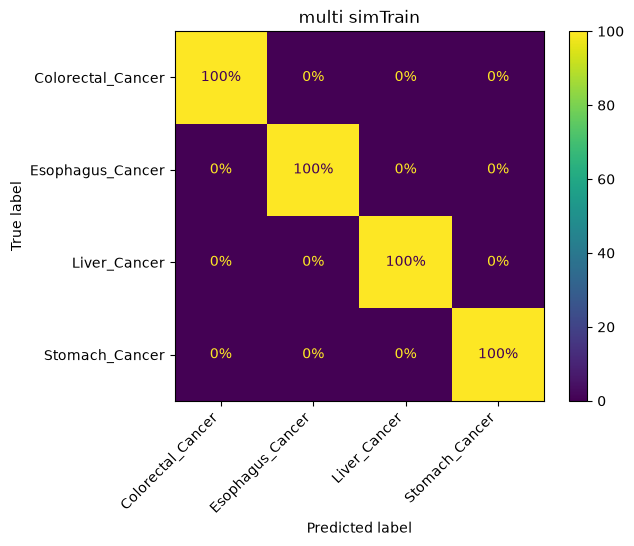

simTrain.shape : (121999, 1525)


2026-11-20 13:13:35,502 WARNING archiveUtilities.py saveFigure() line:200] [saved : /private/home/aedavids/graceM/src/jupyterNotebooks/multiClassifier.out/elifeMultiClassifierFrom400BinaryDropHealthyLung/img/simTrain_elifeMultiClassifierFrom400BinaryDropHealthyLung-confusion-matrix.png]
2026-11-20 13:13:36,359 WARNING archiveUtilities.py saveFigure() line:203] [saved : /private/home/aedavids/graceM/src/jupyterNotebooks/multiClassifier.out/elifeMultiClassifierFrom400BinaryDropHealthyLung/img/simTrain_elifeMultiClassifierFrom400BinaryDropHealthyLung-confusion-matrix.pdf]


'/private/home/aedavids/graceM/src/jupyterNotebooks/multiClassifier.out/elifeMultiClassifierFrom400BinaryDropHealthyLung/img/simTrain_elifeMultiClassifierFrom400BinaryDropHealthyLung-confusion-matrix.png'

In [ ]:
def displayCM(dataSet : str = "real"):
    
    validDataSets = ["simTrain", "simVal", "simTest", "real"]
    if not dataSet in validDataSets :
        logger.error(f"invalide dataSet : {dataSet} should be key with value {validDataSets}")
        return
    diagnosticBundle = runConfig_G.dataDict['multi']
    mb =  getattr(diagnosticBundle, dataSet)
    mb.X.shape
    display(mb.cmDisplay.figure_)
    
print(f'{runConfig_G.dataSetName}')
displayCM('simTrain')

def getConfusionMatrixFigure(dataSet : str) -> figure:
    ''' 
    TODO
    '''
    validDataSets = ["simTrain", "simVal", "simTest", "real"]
    if not dataSet in validDataSets :
        logger.error(f"invalide dataSet : {dataSet} should be key with value {validDataSets}")
        return
    
    diagnosticBundle = runConfig_G.dataDict['multi']
    mb =  getattr(diagnosticBundle, dataSet)
    print(f'{dataSet}.shape : {mb.X.shape}') 
    fig = mb.cmDisplay.figure_
    
    return fig
  
# save pgn and pdf versions  
CMSimTrainFig = getConfusionMatrixFigure('simTrain')
simTrainTitle = f'{runConfig_G.dataSetName}  confusion matrix'
saveFigure(CMSimTrainFig, simTrainTitle, runConfig_G.imgOutDir, 'simTrain')


elifeMultiClassifierFrom400BinaryDropHealthyLung


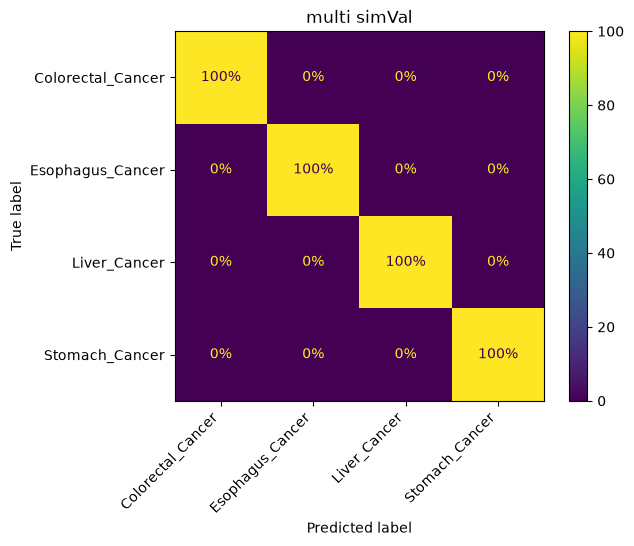

simVal.shape : (40666, 1525)


2026-11-20 13:13:37,581 WARNING archiveUtilities.py saveFigure() line:200] [saved : /private/home/aedavids/graceM/src/jupyterNotebooks/multiClassifier.out/elifeMultiClassifierFrom400BinaryDropHealthyLung/img/simVal_elifeMultiClassifierFrom400BinaryDropHealthyLung-confusion-matrix.png]
2026-11-20 13:13:38,452 WARNING archiveUtilities.py saveFigure() line:203] [saved : /private/home/aedavids/graceM/src/jupyterNotebooks/multiClassifier.out/elifeMultiClassifierFrom400BinaryDropHealthyLung/img/simVal_elifeMultiClassifierFrom400BinaryDropHealthyLung-confusion-matrix.pdf]


'/private/home/aedavids/graceM/src/jupyterNotebooks/multiClassifier.out/elifeMultiClassifierFrom400BinaryDropHealthyLung/img/simVal_elifeMultiClassifierFrom400BinaryDropHealthyLung-confusion-matrix.png'

In [12]:
print(f'{runConfig_G.dataSetName}')

displayCM('simVal')

# save pgn and pdf versions  
CMSimValFig = getConfusionMatrixFigure('simVal')
simValTitle = f'{runConfig_G.dataSetName}  confusion matrix'
saveFigure(CMSimValFig, simValTitle, runConfig_G.imgOutDir, 'simVal')


# Evaluate Models train on simulated data using Real hold out examples

elifeMultiClassifierFrom400BinaryDropHealthyLung


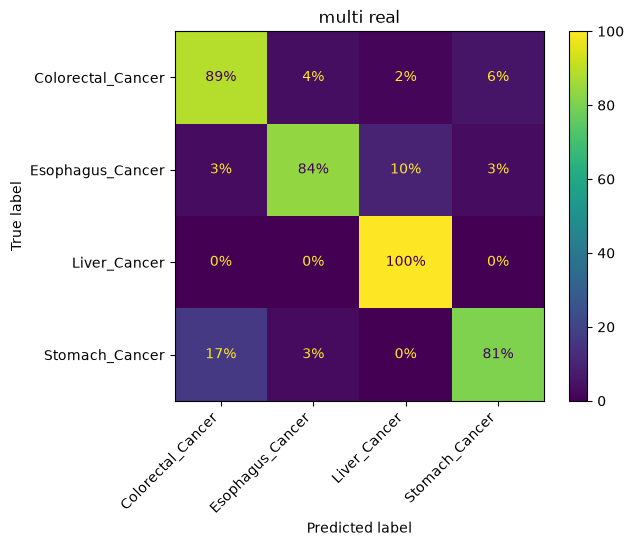

real.shape : (146, 1525)


2026-11-20 13:13:39,605 WARNING archiveUtilities.py saveFigure() line:200] [saved : /private/home/aedavids/graceM/src/jupyterNotebooks/multiClassifier.out/elifeMultiClassifierFrom400BinaryDropHealthyLung/img/real_elifeMultiClassifierFrom400BinaryDropHealthyLung-confusion-matrix.png]
2026-11-20 13:13:40,449 WARNING archiveUtilities.py saveFigure() line:203] [saved : /private/home/aedavids/graceM/src/jupyterNotebooks/multiClassifier.out/elifeMultiClassifierFrom400BinaryDropHealthyLung/img/real_elifeMultiClassifierFrom400BinaryDropHealthyLung-confusion-matrix.pdf]


'/private/home/aedavids/graceM/src/jupyterNotebooks/multiClassifier.out/elifeMultiClassifierFrom400BinaryDropHealthyLung/img/real_elifeMultiClassifierFrom400BinaryDropHealthyLung-confusion-matrix.png'

In [13]:
print(f'{runConfig_G.dataSetName}')
displayCM('real')

# save pgn and pdf versions  
CMrealFig = getConfusionMatrixFigure('real')
CMrealFigTitle = f'{runConfig_G.dataSetName}  confusion matrix'
saveFigure(CMrealFig, CMrealFigTitle, runConfig_G.imgOutDir, 'real')

## <span style="color:red;background-color:yellow;">10/5/26 create final artwork for ExtD Figure: F-r3-4</span>

elifeMultiClassifierFrom400BinaryDropHealthyLung
simTrain.shape : (121999, 1525)
simVal.shape : (40666, 1525)
real.shape : (146, 1525)


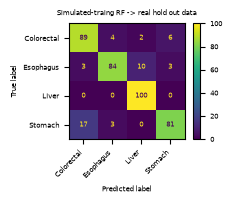

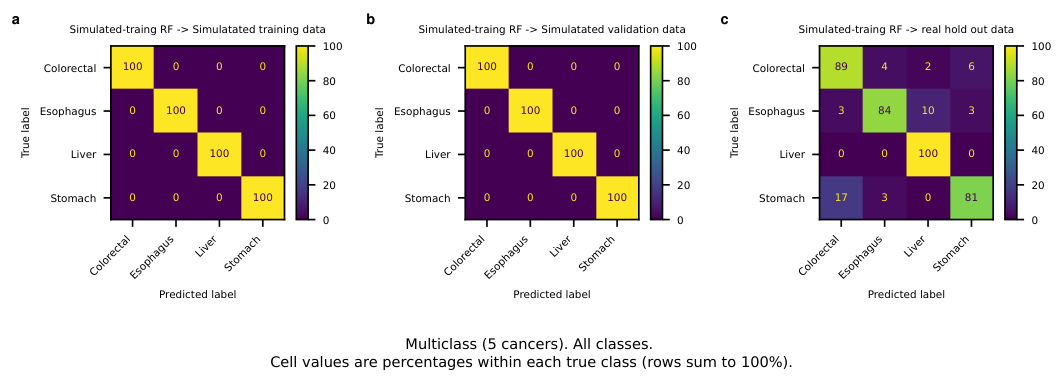

save : /private/home/aedavids/graceM/src/jupyterNotebooks/multiClassifier.out/elifeMultiClassifierFrom400BinaryDropHealthyLung/img/panel/manuscript/ExtD_F_r3_4_cmPanel.pdf


<Figure size 708.661x39.3701 with 0 Axes>

In [27]:
def ExtDF_r3_4FinalArtwork():
    ''' 
    lots of help from chatGPT figuring out how make cm plots 
    final artwork complient. It would have been easier and cleaner
    to just recreate the plots
    
    https://scikit-learn.org/stable/modules/generated/sklearn.metrics.ConfusionMatrixDisplay.html#sklearn.metrics.ConfusionMatrixDisplay

    arguments:
        cmapstr or matplotlib Colormap, default=’viridis

        axmatplotlib Axes, default=None

        does not look like we can set the fontsize ?
    
    '''
    print(f'{runConfig_G.dataSetName}')

    figList = list()
    
    CMSimTrainFig = getConfusionMatrixFigure('simTrain')
    figList.append(CMSimTrainFig)
    CMSimTrainAx = CMSimTrainFig.get_axes()[0]
    CMSimTrainAx.set_title('Simulated-traing RF -> Simulatated training data')
    # display(CMSimTrainFig)
    
    CMSimValFig = getConfusionMatrixFigure('simVal')
    figList.append(CMSimValFig)
    CMSimValAx = CMSimValFig.get_axes()[0]
    CMSimValAx.set_title('Simulated-traing RF -> Simulatated validation data')
    # display(CMSimValFig)

    CMrealFig = getConfusionMatrixFigure('real')
    figList.append(CMrealFig)
    CMRealAx = CMrealFig.get_axes()[0]
    CMRealAx.set_title('Simulated-traing RF -> real hold out data')
    # displayCM('real')

    # make figures nat bio med eng final artwork complient
    tmpList = deepcopy(figList)
    figList = tmpList
    
    fontSize = 5 #7
    legendHeightMm = 10
    panelWidthMm = 180 
    panelHeightMm = 65 - legendHeightMm #80 #70 #65 
    nCols = 3
    nRows = 1

    for fig in figList:
        # Resize the entire figure first.
        fig.set_size_inches(
            (panelWidthMm / nCols) / 25.4,
            (panelHeightMm / nRows) / 25.4,
            forward=True,
        )

        matrixAx, colorbarAx = fig.axes

        # Format the matrix text.
        matrixAx.tick_params(axis="both", labelsize=fontSize)
        matrixAx.xaxis.label.set_fontsize(fontSize)
        matrixAx.yaxis.label.set_fontsize(fontSize)
        matrixAx.title.set_fontsize(fontSize)

        for text in matrixAx.texts:
            # the cells are too small 100% does not look good
            # get rid of the percent sign, add it to the y-axis label
            text.set_text(text.get_text().replace("%", ""))
            text.set_fontsize(fontSize)
            
        # Preserve tick positions; shorten only their displayed labels.
        # the matrices are a little to small
        matrixAx.set_xticks(
            matrixAx.get_xticks(),
            labels=[
                text.get_text().removesuffix("_Cancer")
                for text in matrixAx.get_xticklabels()
            ],
        )

        matrixAx.set_yticks(
            matrixAx.get_yticks(),
            labels=[
                text.get_text().removesuffix("_Cancer")
                for text in matrixAx.get_yticklabels()
            ],
        )

        # Format the colorbar text.
        colorbarAx.tick_params(axis="both", labelsize=fontSize)
        colorbarAx.yaxis.label.set_fontsize(fontSize)
        colorbarAx.yaxis.get_offset_text().set_fontsize(fontSize)

        # Calculate the layout at the final figure size.
        fig.tight_layout()
        fig.canvas.draw()

        # Prevent automatic layout from moving the colorbar afterward.
        fig.set_layout_engine(None)

        # Get the matrix's actual position after enforcing square cells.
        matrixPosition = matrixAx.get_position()
        figureWidthMm = fig.get_figwidth() * 25.4

        gapMm = 2
        colorbarWidthMm = 2

        # Disable automatic colorbar positioning and aspect constraints.
        colorbarAx.set_axes_locator(None)
        colorbarAx.set_box_aspect(None)
        colorbarAx.set_aspect("auto")
        
        # the cm cells are to small to display 100%
        # colorbarAx.set_ylabel("Percentage of true class (%)", fontsize=5)
        
        # Match the colorbar height to the matrix.
        colorbarAx.set_position([
            matrixPosition.x1 + gapMm / figureWidthMm,
            matrixPosition.y0,
            colorbarWidthMm / figureWidthMm,
            matrixPosition.height,
        ])

    display(fig)
    outFileStem='ExtD_F_r3_4_cmPanel'
    F_r_OutputStem = f'{runConfig_G.imgPanelOutDir}/manuscript/{outFileStem}'
    
    legendFig = plt.figure(
                        figsize=(panelWidthMm / 25.4, legendHeightMm / 25.4)
                    )

    legendFig.text(
        0.5, 0.5,
        "Multiclass (5 cancers). All classes. \n"
        "Cell values are percentages within each true class "
        "(rows sum to 100%).",
        ha="center",
        va="center",
        fontsize=7,
    )
    
    t = combineFigures(
                figList,
                F_r_OutputStem,
                widthMm=panelWidthMm,
                heightMm=panelHeightMm,
                nRows=nRows,
                nCols=nCols,
                legendFigure=legendFig,
                legendHeightMm=legendHeightMm
                )
    
    testPdfPath, testPngPath = t
    displayPDFInNotebook(testPdfPath)
    print(f'save : {testPdfPath}')
    
    # plt.show()
    
ExtDF_r3_4FinalArtwork()

In [28]:
# logger.warning("AEDWIP TODO REFACTOR")


# def displaySensitivityAndSpecificity(runConfig : ModelConfig) -> pd.DataFrame:
#     sensitivities = []
#     specificities = [] 
#     auc = []
#     indicies = []
#     controlClass = "Healthy_donor"
#     for key, db in runConfig.dataDict.items():
#         realModel = db.real 
#         sDict = realModel.statsDict
#         for kclass, statsDict in sDict.items():
#             if kclass == controlClass:
#                 continue
#             indicies.append(kclass)
#             sensitivities.append(statsDict['sensitivity'] )
#             specificities.append(statsDict['specificity'])
#             auc.append(statsDict['auc'])

#     retDF =  pd.DataFrame( data={
#                                 "sensitivity" : sensitivities,
#                                 "specificity" : specificities,
#                                 "auc" : auc,
#                                 },
#                             index=indicies )#.round(2)
    
#     return retDF


# sensAndSpecDF = displaySensitivityAndSpecificity(runConfig_G)
# op = f'{runConfig_G.imgOutDir}/sensitivityAndSpecificityReal.png'
# saveDataFrameImage(sensAndSpecDF.round(3), outPath=op, maxRows=None)
# print(f'saving {op}')
# print(f'\n{runConfig_G.dataSetName} real Data Set Sensitivity (True Positive Rate) and Specificity (True Negative Rate)')
# display( sensAndSpecDF )

# op =  f'{runConfig_G.outDirPath}/sensitivityAndSpecificityReal.csv'
# sensAndSpecDF.to_csv( op, index=None)
# print(f'saving : {op}')

In [29]:
# if 'Healthy_donor' in runConfig_G.categories:
#     op = f'{runConfig_G.imgOutDir}/sensitivityAndSpecificity.png'
#     print(op)

In [30]:
# # configROCPanel( runConfig_G, "real" )
# def displayModelPlot( dataSet : str = "real", modelBundleAttributeName : str = "rocFig"):
    
#     validDataSets = ["simTrain", "simVal", "simTest", "real"]
#     if not dataSet in validDataSets :
#         logger.error(f"invalide dataSet : {dataSet} should be key with value {validDataSets}")
#         return
#     diagnosticBundle = runConfig_G.dataDict['multi']
#     mb =  getattr(diagnosticBundle, dataSet)
#     fig = getattr(mb, modelBundleAttributeName)
#     display(fig)
    
    
# print(f'{runConfig_G.dataSetName}')
# displayModelPlot("real", "rocFig")

In [31]:
# def multiClassifierVolcanoPlot( runConfig : ModelConfig):
#     ''' 
#     TODO
#     '''    
#     # get a list of deseq results files
#     drType = runConfig.deseqResultsType
#     searchStr = f'{runConfig.simulatedDataPath}/*/*.{drType}'
#     resultsFileList = glob.glob( searchStr )        
    
#     #print(resultsFileList)
    
#     diagnosticBundle = runConfig.dataDict['multi']
#     resultsDict = diagnosticBundle.real.resultsDict
#     save = False
#     if resultsDict :
#         save = True
    
#     figs = []
#     prefix = "volcano"
#     for rPath in resultsFileList:
#         print(f'rPath :\n{rPath}')
#         # tmp is something like Healthy_donor_vs_all.results
#         tmp = rPath.split("/")[-1]
#         # title is something like Healthy_donor_vs_all
#         title = tmp.split(".")[0]
#         #print(title)
#         fig = volcanoPlotWithBaseMean(rPath,  title)
#         figs.append(fig)
        
#         if save:
#             volcanoPlotPath = saveFigure(fig,  title, runConfig.imgOutDir, prefix)
#             key = f'volcanoFig_{title}'
#             resultsDict[key] = volcanoPlotPath
        
#         # close fig we will combine all the fist into a single panel
#         plt.close(fig)

#     panelFig = make_panel(figs, ncols=3, mode="uniform", cm_shared_scale=True, hide_colorbars=True, 
#                        titles=None,
#                        displayAsPrecentage=True
#                        )
#     # figTitle = "dataSet"
#     panelTitle = f'{runConfig.dataSetName} {runConfig.deseqResultsType}'
#     panelFig.suptitle( panelTitle )
#     plt.show()    
        
#     imgPath = saveFigure(panelFig, panelTitle, runConfig.imgPanelOutDir, prefix)
#     key = f"{runConfig.dataSetName}_{runConfig.deseqResultsType}'volcanoPanel'"
#     runConfig.savePanelDict[key] = imgPath        

# print(f'{runConfig_G.dataSetName}')
# multiClassifierVolcanoPlot(runConfig_G)

elifeMultiClassifierFrom400BinaryDropHealthyLung
/scratch/aedavids/fagazi/simulatedData/elifeMultiClassifierFrom400Binary.sh.out_best400_results/upsetPlot.out/best400_results-allDegrees.png


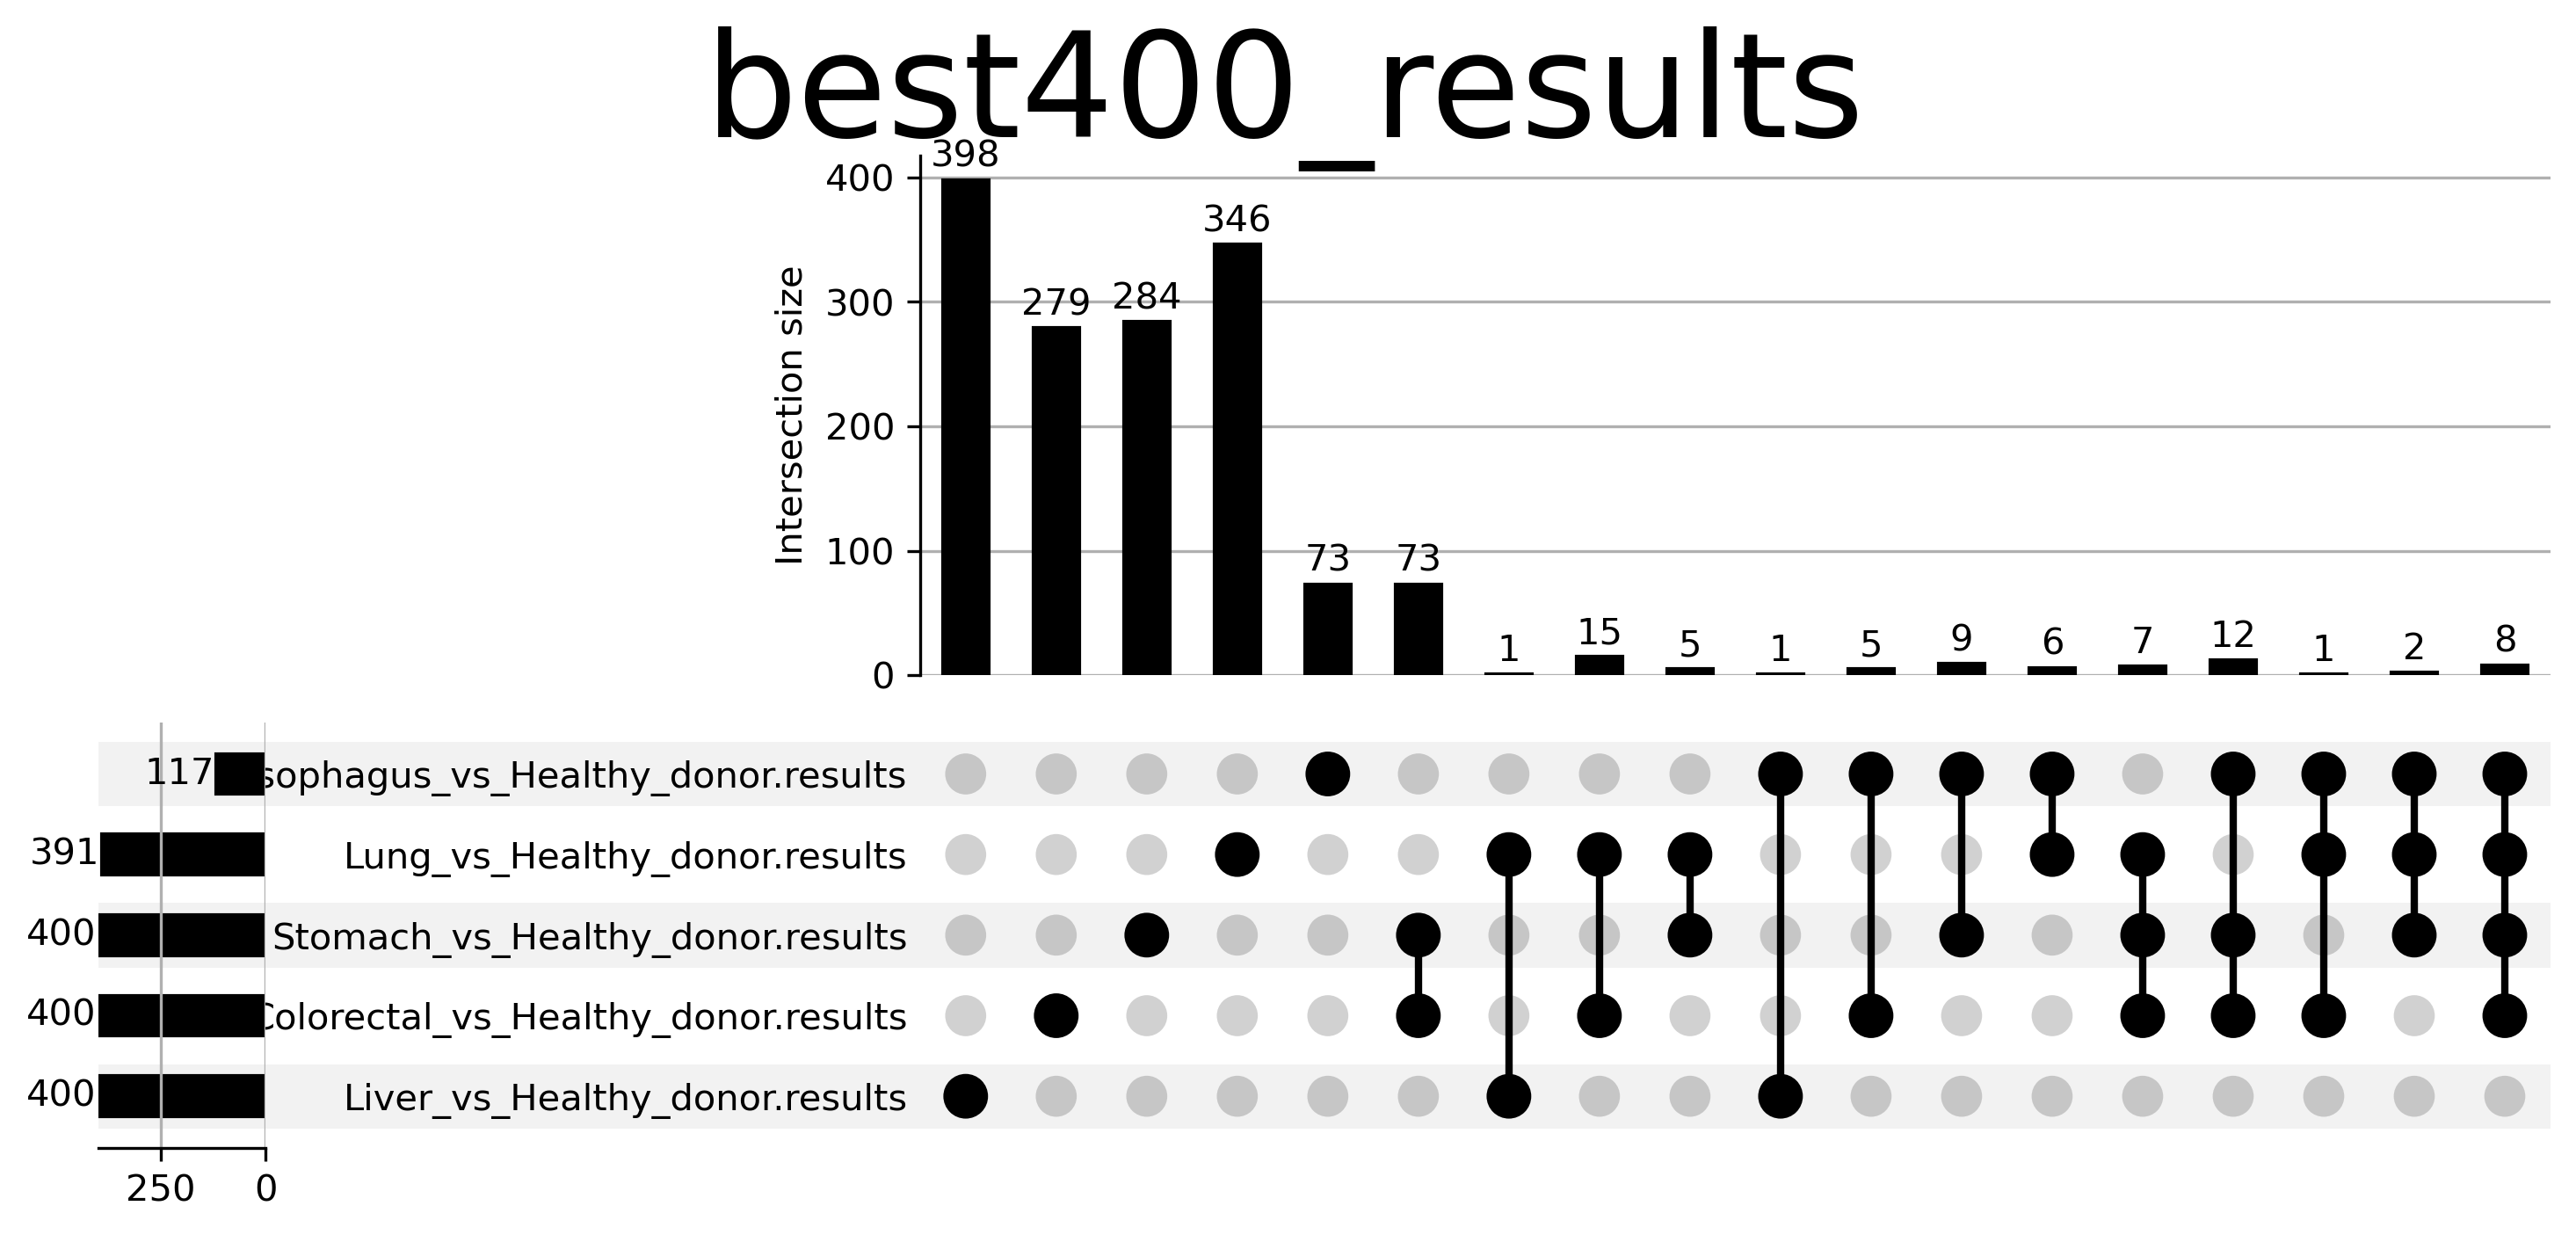

In [32]:
def displayUpsetPlot( config : ModelConfig) -> Image:
    ''' 
    displays the upsetPlot.out/*allDegrees.png created
    during sample generations proces, "step 1 find genes"
    in a Jupyter Notebook cell
    
    image path will be added to archive
    
    returns:
        an Image object. juypter notebook will automatically display this value
        
        Note:            
            use:
                 displayUpsetPlot(config)
                 
            img = displayUpsetPlot(config) will not display the image


    '''
    fp = f'{config.simulatedDataPath}/upsetPlot.out/*allDegrees.png'
    imgPath = glob.glob(fp)[0]
    print(imgPath)
    retImg = Image(imgPath, width=600, height=600)

    key = f"{config.dataSetName}_{config.deseqResultsType}'upsetPlot'"
    config.savePanelDict[key] = imgPath  
    
    return retImg
    
print(f'{runConfig_G.dataSetName}')
displayUpsetPlot(runConfig_G)

# Calculate Sensitivity @ Specificity

In [33]:
# def calculateSensitivityAtSpecificty(
#         config : ModelConfig
#     ):
#     """ 
#     TODO
    
#     similar to binary version
#     """ 

#     t = configMultiCalculateSensitivityAtSpecificity(config,
#                                                     specifityTargets = [0.9]
#                                                     )
#     senitivityAtSpecificityDF = t
    
#     savePath = f'{config.outDirPath}/{config.dataSetName}_SensAtSpec.csv'
#     senitivityAtSpecificityDF.to_csv(savePath, index=False)
    
#     config.resultsDict['senitivityAtSpecificity'] = savePath
#     logger.warning(f'saving : {savePath}')
    
#     return senitivityAtSpecificityDF

# if 'Healthy_donor' in runConfig_G.categories:
#     print(f'\ndataSet {runConfig_G.dataSetName} Real Data')
#     senitivityAtSpecificityDF = calculateSensitivityAtSpecificty(runConfig_G)
#     op = f'{runConfig_G.imgOutDir}/sensitivityAtSpecifictyReal.png'
#     saveDataFrameImage(senitivityAtSpecificityDF.round(3), outPath=op, maxRows=None)
#     print(f'saving {op}')
#     display(senitivityAtSpecificityDF)
# else :
#     print(f'Healthy_donor not include senitivityAtSpecificity is not defined')

In [34]:
# save trained models
archive(runConfig_G)

2026-11-20 13:16:43,801 WARNING saveDataTypes.py saveTrainedModel() line:112] [saved /private/home/aedavids/graceM/src/jupyterNotebooks/multiClassifier.out/elifeMultiClassifierFrom400BinaryDropHealthyLung/multi/trainedModel/model.joblib]
2026-11-20 13:16:43,857 WARNING saveDataTypes.py saveDiagnosticBundle() line:176] [saved : /private/home/aedavids/graceM/src/jupyterNotebooks/multiClassifier.out/elifeMultiClassifierFrom400BinaryDropHealthyLung/multi/archive_multi.json]
2026-11-20 13:16:43,867 WARNING saveDataTypes.py archiveModels() line:78] [saved : /private/home/aedavids/graceM/src/jupyterNotebooks/multiClassifier.out/elifeMultiClassifierFrom400BinaryDropHealthyLung/archive.json]


## <span style="color:red; background-color:yellow;"> TODO AEDWIP feature importance</span>

In [35]:
# from plots.plotFeatureImportance import plotFeatureImportance
# from stats.calculateFeatureImportance import calculateFeatureImportance

**Random Forest built-in feature importance**.  
Random forests rank features by how much they reduce Gini impurity. A node is pure when it contains mostly one class (low Gini) and mixed when it contains multiple classes (high Gini).

feature importance are normalized. ie. they sum to 1. I.E. this is a relative measure of importance. If feature X has an importance of 0.25 and Y has an importance of 0.5, Y is twice as important as X.

In [36]:
# geneAnnotationPath = "/private/groups/kimlab/aedavids/fagazi/simulatedData/allGeneListElife1vsAll.annotions.csv"
# # we can not set index_col = ensemble_id becuase repeat mask entries are NaN
# geneAnnotationsDF = pd.read_csv(geneAnnotationPath)
# print(geneAnnotationsDF.shape)
# print(geneAnnotationsDF.columns)
# geneAnnotationsDF.head()

In [37]:
# from stats.calculateFeatureImportance import calculateFeatureImportanceAndPlot

# topN = 100
# title = f"{runConfig_G.dataSetName} Random Forest Simulated Training Gini Impurity Index "
# t = calculateFeatureImportanceAndPlot(runConfig_G, 
#                                       geneAnnotationsDF, 
#                                       topN=topN, 
#                                       diagnosticBundleKey='multi',
#                                       title=title,
#                                       method="built-in"
#                                       )
# fig,panel, giniFeatureImportanceDF = t

In [38]:
# print(giniFeatureImportanceDF.shape)
# display( giniFeatureImportanceDF) #.head(n=5) )

In [39]:
logger.warning("END NOTEBOOK")
elapsed = time.time() - notebook_start_time
hours, rem = divmod(elapsed, 3600)
minutes, seconds = divmod(rem, 60)
print(f"✅ Notebook completed in {int(hours)}h {int(minutes)}m {seconds:.1f}s.")

2026-11-20 13:16:43,924 WARNING 2279843384.py <module>() line:1] [END NOTEBOOK]


✅ Notebook completed in 0h 7m 10.9s.
